In [13]:
import cv2
import mediapipe as mp
import numpy as np
import matplotlib.pyplot as plt

In [14]:
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

model_path = "../models/face_landmarker.task"

base_options = python.BaseOptions(
    model_asset_path=model_path
)

options = vision.FaceLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1
)

detector = vision.FaceLandmarker.create_from_options(options)

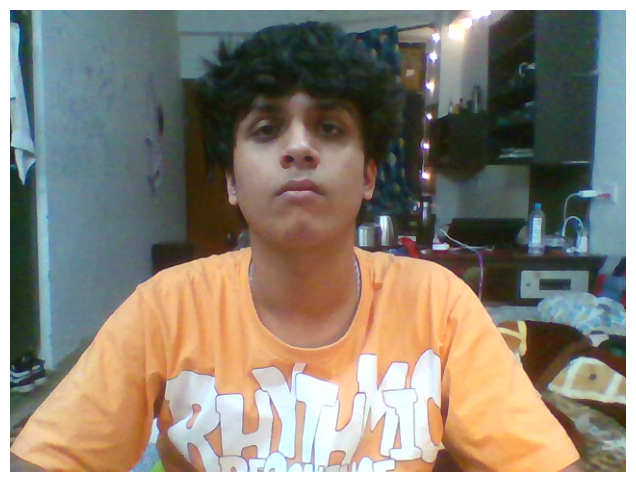

In [15]:
cap = cv2.VideoCapture(0)

ret, frame = cap.read()

cap.release()

if not ret:
    raise RuntimeError("Unable to capture image")

h, w, _ = frame.shape

rgb_frame = cv2.cvtColor(
    frame,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(8, 6))
plt.imshow(rgb_frame)
plt.axis("off");

In [17]:
mp_image = mp.Image(
    image_format=mp.ImageFormat.SRGB,
    data=rgb_frame
)

results = detector.detect(mp_image)

if not results.face_landmarks:
    raise RuntimeError("No face detected")

landmarks = results.face_landmarks[0]

print("Total landmarks:", len(landmarks))

Total landmarks: 478


In [18]:
landmark_indices = [1, 152, 33, 263, 61, 291]
image_points = []

for index in landmark_indices:

    x = landmarks[index].x * w
    y = landmarks[index].y * h

    image_points.append([x, y])

image_points = np.array(
    image_points,
    dtype=np.float64
)

print(image_points)

[[300.51668167 149.32459831]
 [302.90302277 239.66855049]
 [255.5880928  128.59846115]
 [343.66165161 125.78507423]
 [275.4076004  192.51022339]
 [326.13574982 192.08950996]]


In [19]:
model_points = np.array([

    (0.0, 0.0, 0.0),          # Nose tip

    (0.0, -330.0, -65.0),     # Chin

    (-225.0, 170.0, -135.0),  # Left eye corner

    (225.0, 170.0, -135.0),   # Right eye corner

    (-150.0, -150.0, -125.0), # Left mouth corner

    (150.0, -150.0, -125.0)   # Right mouth corner

], dtype=np.float64)

In [20]:
focal_length = w

camera_matrix = np.array([

    [focal_length, 0, w / 2],

    [0, focal_length, h / 2],

    [0, 0, 1]

], dtype=np.float64)

distortion_coefficients = np.zeros((4, 1))

print(camera_matrix)

[[640.   0. 320.]
 [  0. 640. 240.]
 [  0.   0.   1.]]


In [21]:
success, rotation_vector, translation_vector = cv2.solvePnP(

    model_points,

    image_points,

    camera_matrix,

    distortion_coefficients,

    flags=cv2.SOLVEPNP_ITERATIVE

)

print("Pose estimation successful:", success)

Pose estimation successful: True


In [22]:
rotation_matrix, _ = cv2.Rodrigues(
    rotation_vector
)

print(rotation_matrix)

[[ 0.99893908 -0.02905693  0.03572674]
 [-0.02609882 -0.99640106 -0.080646  ]
 [ 0.03794148  0.07962801 -0.99610232]]


In [23]:
angles, _, _, _, _, _ = cv2.RQDecomp3x3(
    rotation_matrix
)

pitch = angles[0]
yaw = angles[1]
roll = angles[2]

print("Pitch:", round(pitch, 2))
print("Yaw:", round(yaw, 2))
print("Roll:", round(roll, 2))

Pitch: 175.43
Yaw: -2.17
Roll: -1.5


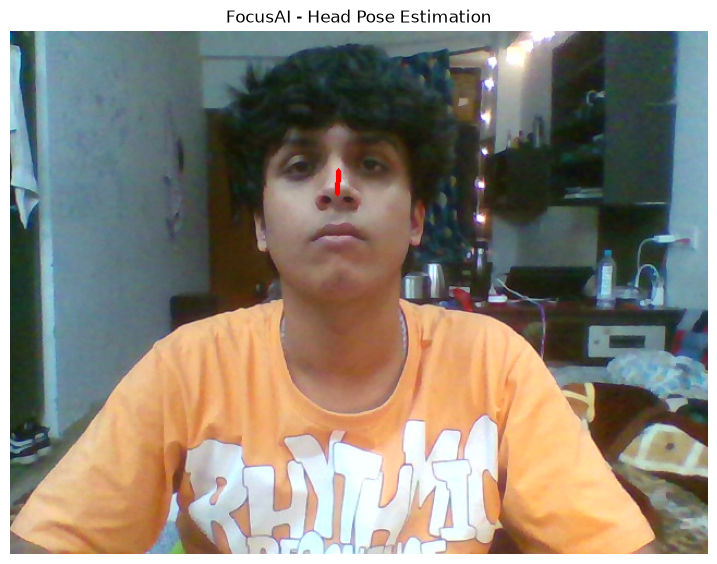

In [24]:
nose_point = image_points[0].astype(int)

nose_end_3d = np.array([
    (0.0, 0.0, 500.0)
], dtype=np.float64)

nose_end_2d, _ = cv2.projectPoints(
    nose_end_3d,
    rotation_vector,
    translation_vector,
    camera_matrix,
    distortion_coefficients
)

nose_end = tuple(
    nose_end_2d.reshape(-1, 2)[0].astype(int)
)

annotated = frame.copy()

cv2.line(
    annotated,
    tuple(nose_point),
    nose_end,
    (0, 0, 255),
    3
)

annotated_rgb = cv2.cvtColor(
    annotated,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(9, 7))
plt.imshow(annotated_rgb)
plt.title("FocusAI - Head Pose Estimation")
plt.axis("off");

In [25]:
if yaw < -15:
    direction = "TURNED LEFT"

elif yaw > 15:
    direction = "TURNED RIGHT"

elif pitch < -15:
    direction = "LOOKING DOWN"

elif pitch > 15:
    direction = "LOOKING UP"

else:
    direction = "FORWARD"

print("Head direction:", direction)

Head direction: LOOKING UP
